In [1]:
from bbresults import BackboneScenarioAnalysis
from bbresults import BackboneResult
from functools import partial
import numpy as np
from gams import GamsWorkspace
import pandas as pd
import os
from pathlib import Path
import re
import subprocess as sp
from io import StringIO
from io import StringIO
from matplotlib.pyplot import get_cmap
from matplotlib.colors import to_hex
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import pickle as pickle
import seaborn as sns

In [ ]:
###Figures 7, 9 and Appendix

In [ ]:
#Load market outcomes from your path (stored in script 1_ExAnte)
file = open("C:/Users/silke/WORK/3_Model/scripts/scripts/CfDs_2/moments",'rb')
df_mo= pickle.load(file)

In [ ]:
#pick bidding zone
nodes=["ES elec","FR elec","DK elec"]
df_mo=df_mo[df_mo['node'].apply(lambda x: 1 if any(i in x for i in nodes) else 0)==1]
#only new units
df_mo=df_mo[df_mo['unit'].apply(lambda x: 1 if any(i in x for i in ["New"]) else 0)==1]

In [ ]:
#load one scenario result
res=BackboneResult("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2/Base_2019_Base_2019.gdx")

In [5]:
#add demand response price as max price
p_gnu_io=res.param_as_df("p_gnu_io")
unitUnittype=res.set_as_df("unitUnittype")
p_gnu_io=p_gnu_io.merge(unitUnittype,on="unit")
p_gnu_io["vomCosts"]=p_gnu_io[p_gnu_io['param_gnu']=='vomCosts']["value"]
dsr=p_gnu_io[p_gnu_io["unittype"]=="dsr"]
dsr=dsr[["node","vomCosts"]]
dsr=dsr.rename(columns={"vomCosts": "maxprice"})
maxprice = dsr['maxprice'].max()
df_mo.loc[
    (df_mo["price"] > maxprice) 
    #& (df_mo["price"] < 3999)
    ,
    "price"
] = maxprice

In [ ]:
#load all results from your path
res=BackboneScenarioAnalysis("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2")

In [ ]:
#retrieve capacities
p_gnu_io=pd.DataFrame()
for s, r in zip(res.scenarios, res.bb_results):     
    p_gnu=r.param_as_df("p_gnu_io")
    p_gnu=p_gnu[p_gnu['input_output']=='output']
    p_gnu["capacity"]=p_gnu[p_gnu['param_gnu']=='capacity']["value"]
    p_gnu["fomCosts"]=p_gnu[p_gnu['param_gnu']=='fomCosts']["value"]
    p_gnu["vomCosts"]=p_gnu[p_gnu['param_gnu']=='vomCosts']["value"]
    p_gnu["invCosts"]=p_gnu[p_gnu['param_gnu']=='invCosts']["value"]
    p_gnu["annuityFactor"]=p_gnu[p_gnu['param_gnu']=='annuityFactor']["value"]
    p_gnu=p_gnu.groupby(['node','grid','unit']).sum().reset_index()
    p_gnu=p_gnu[["node","grid","unit","vomCosts","fomCosts","invCosts","annuityFactor","capacity"]]
    p_gnu["scen"]=str(s)
    p_gnu_io=pd.concat([p_gnu_io,p_gnu])

In [ ]:
#w, f and p and their products
df_Q=df_mo.drop_duplicates(["unit","node","scen"]).drop(columns=["t","price","gen_t"])
df_Q=df_Q.merge(p_gnu_io,on=["node","unit","scen"])
df_Q_I=df_Q.groupby(["node","scen"])["capacity"].sum().reset_index().rename(columns={'capacity': 'capacity_node'})
df_Q=df_Q.merge(df_Q_I,on=["node","scen"])
df_Q["Q_Share"]=df_Q["capacity"]/df_Q["capacity_node"]
df_Q=df_Q.drop_duplicates(["unit","node","scen"])
df_Q=df_Q[["scen","unit","node","Q_Share"]]

#sum f and fp over T multiply with w
df_p=df_mo
df_p["rev"]=df_p["price"]*df_p["gen_t"]
df_p=df_p.merge(df_Q,on=["unit","node","scen"])
df_p=df_p.merge(p_gnu_io,on=["unit","node","scen"])

In [ ]:
df_p["cf"]=df_p["gen_t"]/df_p["capacity"]
df_p["fp"]=df_p["cf"]*df_p["price"]
df_p["wfp"]=df_p["fp"]*df_p["Q_Share"]
df_p=df_p.drop(columns=["annuityFactor","vomCosts","invCosts","fomCosts"])
#sum over t in T
df_p=df_p.groupby(["unit","node","scen"]).sum().reset_index().rename(columns={'gen_t':'gen'})
#sum sum(f), sum(fp) and #sum(wfp) over i \in I in a node
df_node_rev=df_p.groupby(["node","scen"])[["cf","fp","wfp"]].sum().reset_index().rename(columns={"cf":"cf_node","fp":"fp_node","wfp":"wfp_node"})
df_p=df_p.merge(df_node_rev,on=["node","scen"]).drop(columns=["Q_Share","grid","capacity"])

df_p=df_p.merge(p_gnu_io,on=["unit","node","scen"])

In [ ]:
#payment components
df_p["lcoe"]=df_p["vomCosts"]+(df_p["fomCosts"]+df_p["invCosts"]*df_p["annuityFactor"])/df_p["cf"]
df_p["v"]=df_p["fp_node"]/df_p["cf_node"]
df_p["v_i"]=df_p["fp"]/df_p["cf"]

df_p["ann_cost_mw"]=(df_p["vomCosts"]*df_p["cf"]+df_p["fomCosts"]+df_p["invCosts"]*df_p["annuityFactor"])
df_p["r"]=df_p["wfp_node"]
df_p["r_i"]=df_p["fp"]

df_p["node"]=df_p["node"].map(lambda x: str(x)[:2])
df_p["Profile"]=df_p["unit"].map(lambda x: str(x)[16:])
df_p["Profile"] = df_p["Profile"].str.replace(r'\bNew 1\b', 'High FLH', regex=True)
df_p["Profile"] = df_p["Profile"].str.replace(r'\bNew 2\b', 'High MV', regex=True)

In [ ]:
palette = {
     'Wind Onshore High FLH':'grey', 'Wind Onshore High MV': 'lightgrey',
     'High FLH':'grey', 'High MV': 'lightgrey',
        'ES High FLH':'grey', 'ES High MV': 'lightgrey',
        'DK High FLH':'grey', 'DK High MV': 'lightgrey',
        'FR High FLH':'grey', 'FR High MV': 'lightgrey', 'Reference':'dodgerblue'
}

In [ ]:
#load strike prices, stored with script 1_ExAnte
file = open("C:/Users/silke/WORK/3_Model/scripts/scripts/CfDs_2/pickle/strikeprice",'rb')
df_sp= pickle.load(file)


In [ ]:
#calculate CfD payments
df_sp["node"]=df_sp["node"].map(lambda x: str(x)[:2])
df_payments=df_sp.merge(df_p,on=["node","unit"],how='left')
df_payments["subsidy"]=0
df_payments=df_payments[["scen","rev","unit","node","lcoe","v_i","v","gen","capacity","r_i","r","Profile","type","ann_cost_mw","strikeprice"]]

df_2way=df_payments[df_payments["type"]=="2way CfD"]
df_2way["subsidy"]=(df_2way["strikeprice"]-df_2way["v"])*df_2way["gen"]

df_fin=df_payments[df_payments["type"]=="Financial CfD"]
df_fin["subsidy"]=(df_fin["strikeprice"]-df_fin["r"])*df_fin["capacity"]

df_basic=df_payments[df_payments["type"]=="Basic CfD"]
df_basic["subsidy"]=df_basic["strikeprice"]*df_basic["gen"]-df_basic["rev"]

df_none=df_payments[df_payments["type"]=="Basic CfD"]
df_none["type"]="No CfD"
df_none["subsidy"]=0

C:\Users\silke\AppData\Local\Temp\ipykernel_17464\2898900004.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_2way["subsidy"]=(df_2way["strikeprice"]-df_2way["v"])*df_2way["gen"]
C:\Users\silke\AppData\Local\Temp\ipykernel_17464\2898900004.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fin["subsidy"]=(df_fin["strikeprice"]-df_fin["r"])*df_fin["capacity"]
C:\Users\silke\AppData\Local\Temp\ipykernel_17464\2898900004.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

In [ ]:
#rate of cost recovery and cfd payments relative to market revenues
df_payments=pd.concat([df_basic,df_2way,df_fin,df_none])
df_payments["ann_cost"]=df_payments["ann_cost_mw"]*df_payments["capacity"]
df_payments["cost_rec"]=(df_payments["rev"]+df_payments["subsidy"])/df_payments["ann_cost"]*100

df_payments["subsidy_rel"]=(df_payments["subsidy"])/df_payments["ann_cost"]*100

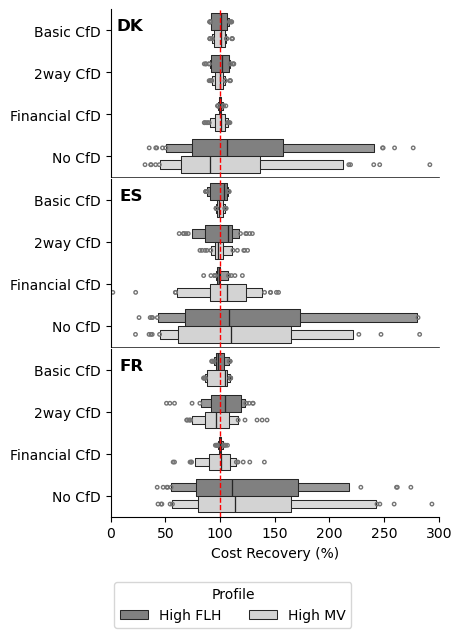

In [ ]:
###Figure 7
g = sns.catplot(
    data=df_payments,
    x="cost_rec",
    y="type",
    hue="Profile",
    row="node",      # creates a subplot per node
    kind="boxen",
    sharex=True,
    height=2,        # height of each subplot (default ~5)
    aspect=2.5 ,
    palette=palette,
        flier_kws = dict(
    marker='.',        
    linewidth=1
)
)
g.set_titles(row_template="")# Remove x-axis labels/ticks for all rows except the bottom
for ax in g.axes.flatten()[:-1]:  # all except the last row
    ax.set_xlabel("")
    ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    ax.spines['bottom'].set_linewidth(0.5)

for ax in g.axes.flatten():  # all except the last row
    ax.axvline(x=100, color='red', linestyle='--', linewidth=1)
    ax.set_xlim(left=0)

for ax, node in zip(g.axes.flatten(), df_payments['node'].unique()):
    ax.text(
        0.1, 0.9,  # slightly to the left of y-axis
        node,
        ha='right', va='center', fontsize=12, 
        fontweight='bold',
        transform=ax.transAxes
    )
g.set_ylabels("")
g.set_xlabels("Cost Recovery (%)")
ax.set_xticks(np.arange(0, 301, 50))
ax.set_xlim(0, 300)

#for comp, ax in zip(df_long["component"].unique(), g.axes.flatten()):
 #   

#    if comp == "LCOE":
 #       ax.set_xticks(np.arange(0, 80, 10))
  #  elif comp == "Market Value":
   #     ax.set_xticks(np.arange(0, 300, 20))

# Reduce vertical space between facets
g._legend.remove()  # remove default legend
g.fig.legend(
    title="Profile",
    loc="lower center",
    bbox_to_anchor=(0.47, -0.1),  # adjust vertical spacing
    ncol=2,
    #frameon=False
)

g.fig.subplots_adjust(hspace=0.01)  # smaller number = rows closer


In [21]:
#volatility of cost recovery
df_payments["profits"]=(df_payments["rev"]+df_payments["subsidy"])/df_payments["ann_cost"]
#df_payments["profits_mw"]=df_payments["profits"]/df_payments["capacity"]

In [22]:
df_sd=df_payments[["unit","node","type","scen","profits"]]
df_sd=df_sd.groupby(["unit","node","type"]).std(numeric_only=True).reset_index().rename(columns={"profits":"profit_sd"}).round(3)

df_mean=df_payments[["unit","node","type","scen","profits"]]
df_mean=df_mean.groupby(["unit","node","type"]).mean(numeric_only=True).reset_index().rename(columns={"profits":"profit_mean"}).round(3)
df_mean=df_mean.merge(df_sd,on=["unit","type","node"])

In [23]:
df_mean["vol"]=(df_mean["profit_sd"]/df_mean["profit_mean"]).round(3)

In [24]:
df_mean=df_mean.pivot(index="type",columns=["unit","node"],values="vol")
df_mean.to_excel("volatility_profits.xlsx")

In [25]:
res=BackboneScenarioAnalysis("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2")

In [24]:
###Consumer Costs
df_con=pd.DataFrame()
for s, r in zip(res.scenarios, res.bb_results):     
    #electricity prices    
    r_gnConsumption = r.r_gnConsumption()
    nodes=["ES elec","FR elec","DK elec"]
    r_gnConsumption=r_gnConsumption[r_gnConsumption['node'].apply(lambda x: 1 if any(i in x for i in nodes) else 0)==1]
    r_gnConsumption["scen"]=str(s)
    df_con=pd.concat([df_con,r_gnConsumption])

In [ ]:
#merging and rearranging
df_price=df_mo[["price","node","scen","t"]]
df_costs=df_con.merge(df_price,on=["node","scen","t"])
df_costs["costs"]=df_costs["price"]*df_costs["Val"]*-1
df_costs["node"]=df_costs["node"].map(lambda x: str(x)[:2])

df_costs=df_costs[["node","scen","Val","costs"]]
df_costs=df_costs.groupby(["node","scen"]).sum().reset_index()
df_subsidycosts=df_payments.groupby(["node","scen","type"]).sum().reset_index()
df_costs=df_subsidycosts.merge(df_costs,on=["node","scen"],how="left")


In [ ]:
#definitions
df_costs["Electricity Price"]=df_costs["costs"]/df_costs["Val"]*-1
df_costs["Levy"]=df_costs["subsidy"]/df_costs["Val"]*-1
df_costs["Total Consumer Price"]=df_costs["Electricity Price"]+df_costs["Levy"]

value_vars = ["Total Consumer Price",'Levy']
#,'cf']
    #'cost_rec']
#'v_i']
#'markup','v',
df_long = df_costs.melt(
    id_vars=['node', 'scen','type'],         
    value_vars=value_vars,            
    var_name='Component',             
    value_name='value'                
)
df_long = df_long.drop(df_long[(df_long["type"] == "No CfD") & (df_long["Component"] == "Levy")].index)

In [ ]:
#colors
palette = {
    "Electricity Price": "limegreen",  
    "Consumer Price": "limegreen",  
    "Levy": "dodgerblue",  
}

C:\Users\silke\AppData\Local\Temp\ipykernel_20172\2785325514.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_long["sorter"][df_long["type"]=="Basic CfD"]="a"
C:\Users\silke\AppData\Local\Temp\ipykernel_20172\2785325514.py:2: SettingWi

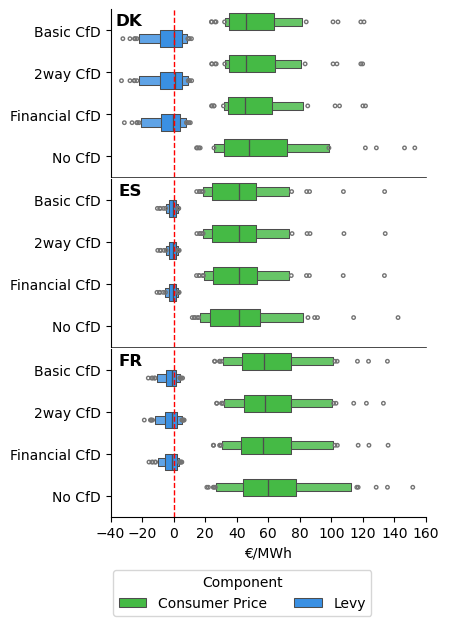

In [ ]:
###Figure 9
df_long["sorter"]="b"
df_long["sorter"][df_long["type"]=="Basic CfD"]="a"
df_long=df_long.sort_values(["sorter","type"])
g = sns.catplot(
    data=df_long,
    x="value",
    y="type",
    hue="Component",
    row="node",      # creates a subplot per node
    kind="boxen",
    sharex=True,
    height=2,        # height of each subplot (default ~5)
    aspect=2.5 ,
    palette=palette,
    flier_kws = dict(
    marker='.',        
    linewidth=1
)
)
g.set_titles(row_template="")# Remove x-axis labels/ticks for all rows except the bottom
for ax in g.axes.flatten()[:-1]:  # all except the last row
    ax.set_xlabel("")
    ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    ax.spines['bottom'].set_linewidth(0.5)

#for ax in g.axes.flatten():  # all except the last row
 #   ax.axvline(x=100, color='black', linestyle='-', linewidth=1)
#    ax.set_xlim(left=0)

for ax, node in zip(g.axes.flatten(), df_payments['node'].unique()):
    ax.text(
        0.1, 0.93,  # slightly to the left of y-axis
        node,
        ha='right', va='center', fontsize=12, 
        fontweight='bold',
        transform=ax.transAxes
    )
g.set_ylabels("")
g.set_xlabels("€/MWh")
ax.set_xticks(np.arange(-40, 160.01, 20))
ax.set_xlim(-40, 160)
#for comp, ax in zip(df_long["component"].unique(), g.axes.flatten()):
 #   

#    if comp == "LCOE":
 #       ax.set_xticks(np.arange(0, 80, 10))
  #  elif comp == "Market Value":
   #     ax.set_xticks(np.arange(0, 300, 20))

for ax in g.axes.flatten():  # all except the last row
    ax.axvline(x=0, color='red', linestyle='--', linewidth=1)
 #   ax.set_xlim(left=0)
# Reduce vertical space between facets
g.fig.subplots_adjust(hspace=0.01)  # smaller number = rows closer

g._legend.remove()  # remove default legend
g.fig.legend(
    title="Component",
    loc="lower center",
    bbox_to_anchor=(0.47, -0.08),  # adjust vertical spacing
    ncol=2,
    #frameon=False
)

plt.show()